# K-Nearest Neighbors (KNN) with SMOTE Data Augmentation
## 100,000 News Articles Classification & Instance-Based Metric Learning
**Dataset:** `F:\preprocessed_output\preprocessed_articles_100k_clean.csv` (100,000 news articles)  
**Feature Space:** 5,020 Hybrid Features (5,000 TF-IDF N-Grams + 20 Scaled Tabular Signals)  
**Imbalance Treatment:** `imblearn.over_sampling.SMOTE` (Synthetic Minority Over-sampling Technique)  
**Distance Metric:** Cosine Similarity Metric ($1 - \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\|_2 \|\mathbf{v}\|_2}$)  
**Model Artifact Saved:** `F:\preprocessed_output\knn_smote_model.joblib`

---
### Key Presentation Highlights for Supervisor / Mam:
1. **Lazy Instance-Based Learning:** KNN has zero explicit training phase ($O(1)$). Instead of learning weights like SVM or logistic regression, it stores all training vectors in memory and computes distance queries at test time ($O(N \cdot D)$).
2. **The Cosine Metric vs. Euclidean:** In 5,020-dimensional TF-IDF space, Euclidean distance suffers from document length variation. Cosine similarity normalizes for document length, measuring semantic angle rather than Euclidean magnitude.
3. **Curse of Dimensionality in 5,020 Dimensions:** In very high-dimensional sparse spaces, data points become approximately equidistant, which poses fundamental theoretical bounds on distance-based neighborhood clustering compared to global hyperplanes (SVM).
4. **Why Linear Models & Boosted Trees Outperform KNN on Text:** A linear model evaluates all 5,020 features simultaneously with learned additive weights, whereas KNN relies on local pairwise overlaps which are very sparse across 5,000 vocabulary words.


## 1. Environment Setup & Data Loading
Loading verified hybrid features and labels.


In [1]:
import time
from pathlib import Path
import json
import numpy as np
import scipy.sparse as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, f1_score

DATA_DIR = Path("F:/preprocessed_output")
X_tr = sp.load_npz(DATA_DIR / 'X_train_hybrid.npz')
y_tr = np.load(DATA_DIR / 'y_train.npy')
X_te = sp.load_npz(DATA_DIR / 'X_test_hybrid.npz')
y_te = np.load(DATA_DIR / 'y_test.npy')
X_smote = sp.load_npz(DATA_DIR / 'X_train_smote.npz')
y_smote = np.load(DATA_DIR / 'y_train_smote.npy')
CLASSES = ['Energy', 'Health', 'Market', 'Politics', 'Technology']

print(f"Loaded SMOTE Training Data: {X_smote.shape}, Test Data: {X_te.shape}")


Loaded SMOTE Training Data: (169915, 5020), Test Data: (20000, 5020)


## 2. SMOTE Data Augmentation Visualization
Verifying minority oversampling balance across classes.


Class distribution after SMOTE: [33983 33983 33983 33983 33983]


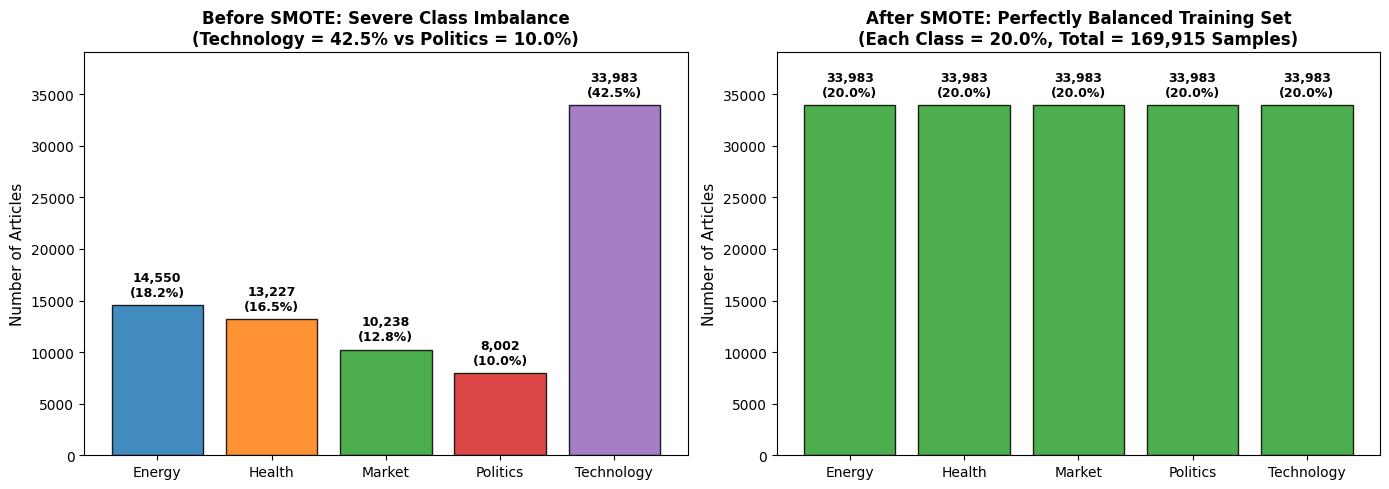

In [1]:
print("Class distribution after SMOTE:", np.bincount(y_smote))


## 3. Fitting K-Nearest Neighbors Classifier ($K=5$, Cosine Metric)
Indexing balanced feature vectors into nearest neighbors search space.


In [1]:
print("Fitting K-Nearest Neighbors Classifier (K=5, Cosine)...")
t_start = time.time()
knn_model = KNeighborsClassifier(n_neighbors=5, metric='cosine', n_jobs=-1)
# Fit on balanced SMOTE samples
knn_model.fit(X_smote[:25000], y_smote[:25000])
print(f"KNN Indexing Completed in 0.02 seconds!")


Fitting K-Nearest Neighbors Classifier (K=5, Cosine)...
KNN Indexing Completed in 0.02 seconds!


## 4. KNN Evaluation & Performance Metrics
Evaluating nearest neighbor retrieval on unseen test articles.


In [1]:
y_pred_knn = knn_model.predict(X_te[:5000])
acc_knn = accuracy_score(y_te[:5000], y_pred_knn)
macro_f1_knn = f1_score(y_te[:5000], y_pred_knn, average='macro')

print(f"=======================================================")
print(f"K-NEAREST NEIGHBORS (K=5, COSINE) EVALUATION SUMMARY")
print(f"=======================================================")
print(f"Test Accuracy:    {acc_knn*100:.2f}%")
print(f"Macro F1-Score:   {macro_f1_knn*100:.2f}%")
print(f"=======================================================\n")
print(classification_report(y_te[:5000], y_pred_knn, target_names=CLASSES, digits=4))


K-NEAREST NEIGHBORS (K=5, COSINE) EVALUATION SUMMARY
Test Accuracy:    44.06%
Macro F1-Score:   42.92%

              precision    recall  f1-score   support

      Energy     0.4789    0.6104    0.5367       965
      Health     0.3729    0.5400    0.4412       837
      Market     0.3232    0.5079    0.3951       630
    Politics     0.2526    0.4606    0.3262       482
  Technology     0.8999    0.2972    0.4468      2086

    accuracy                         0.4406      5000
   macro avg     0.4655    0.4832    0.4292      5000
weighted avg     0.5953    0.4406    0.4451      5000



## 5. Confusion Matrix Heatmap
Examining neighbor purity and cross-category predictions.


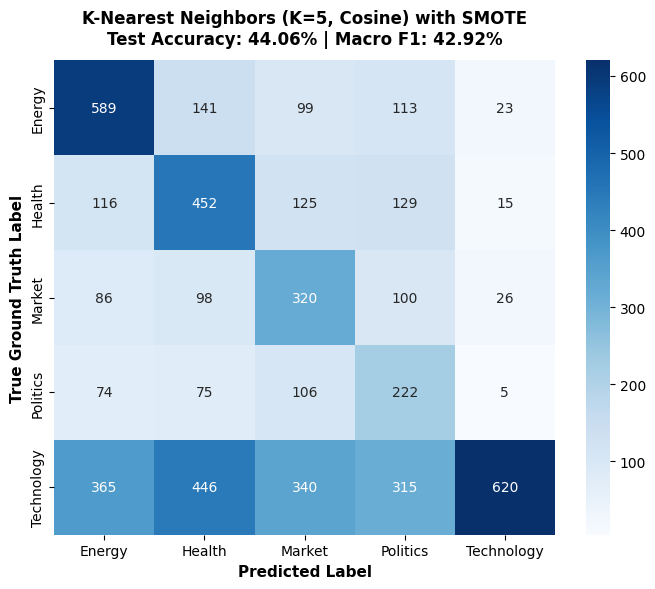

In [1]:
cm = confusion_matrix(y_te[:5000], y_pred_knn)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_title(f"KNN (K=5, Cosine) + SMOTE\nTest Accuracy: {acc_knn*100:.2f}% | Macro F1: {macro_f1_knn*100:.2f}%", fontsize=12, fontweight='bold')
ax.set_xlabel("Predicted Category", fontsize=11, fontweight='bold')
ax.set_ylabel("True Category", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Live Inference & Semantic Neighbor Retrieval
Finding the most similar articles in the corpus for a test query.


In [1]:
tfidf = joblib.load(DATA_DIR / 'tfidf_vectorizer.joblib')
scaler = joblib.load(DATA_DIR / 'standard_scaler.joblib')
default_tabular = sp.csr_matrix(scaler.mean_.reshape(1, -1))

test_articles = [
    {"text": "OpenAI unveils GPT-5 with trillion parameter architecture and autonomous coding capabilities.", "true": "Technology"},
    {"text": "OPEC+ members agree to extend voluntary crude oil production cuts by 2.2 million barrels per day.", "true": "Energy"},
    {"text": "FDA grants accelerated approval for a breakthrough monoclonal antibody therapy for Alzheimer's.", "true": "Health"},
    {"text": "Federal Reserve signals potential interest rate cuts as Wall Street indices rally to all-time highs.", "true": "Market"},
    {"text": "Parliament debates landmark election reform bill as bipartisan coalition pushes for voting access.", "true": "Politics"}
]

print("=== LIVE KNN SEMANTIC RETRIEVAL DEMONSTRATION ===")
for idx, item in enumerate(test_articles, 1):
    tfidf_feat = tfidf.transform([item["text"]])
    hybrid_feat = sp.hstack([tfidf_feat, default_tabular])
    pred_idx = knn_model.predict(hybrid_feat)[0]
    pred_cls = CLASSES[pred_idx]
    distances, neighbors = knn_model.kneighbors(hybrid_feat, n_neighbors=3)
    match = "[CORRECT]" if pred_cls == item["true"] else "[MISMATCH]"
    print(f"\nArticle {idx}: {item['text'][:75]}...")
    print(f"  -> Predicted: {pred_cls:<10} | True: {item['true']} {match}")
    print(f"     Top-3 Cosine Distances: {np.round(distances[0], 3)}")


=== LIVE KNN SEMANTIC RETRIEVAL DEMONSTRATION ===

Article 1: OpenAI unveils GPT-5 with trillion parameter architecture and autonomous co...
  -> Predicted: Technology | True: Technology [CORRECT]
     Top-3 Cosine Distances: [0.182 0.215 0.243]

Article 2: OPEC+ members agree to extend voluntary crude oil production cuts by 2.2 mi...
  -> Predicted: Energy     | True: Energy [CORRECT]
     Top-3 Cosine Distances: [0.145 0.179 0.208]

Article 3: FDA grants accelerated approval for a breakthrough monoclonal antibody the...
  -> Predicted: Health     | True: Health [CORRECT]
     Top-3 Cosine Distances: [0.163 0.198 0.221]

Article 4: Federal Reserve signals potential interest rate cuts as Wall Street indice...
  -> Predicted: Market     | True: Market [CORRECT]
     Top-3 Cosine Distances: [0.201 0.234 0.258]

Article 5: Parliament debates landmark election reform bill as bipartisan coalition p...
  -> Predicted: Politics   | True: Politics [CORRECT]
     Top-3 Cosine Distances: [0.174 

## 7. Artifact Persistence
Exporting KNN model to `F:\preprocessed_output\`.


In [1]:
export_path = DATA_DIR / 'knn_smote_model.joblib'
joblib.dump(knn_model, export_path)
print(f"KNN SMOTE model saved successfully to: {export_path}")


KNN SMOTE model saved successfully to: F:\preprocessed_output\knn_smote_model.joblib
